# Data exploration

In this notebook we will explore the provided data consisting of the wind forecast and power generation.

## Import necessary libraries

In [18]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import FeatureUnion
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error


# helper validation
from sklearn.utils.validation import check_is_fitted

import os
import tarfile
from six.moves import urllib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


## Data acquisition

In [19]:
weather_data_path = "../Data/WeatherForecastInput_A.csv"

training_data_path = "../Data/TrainData_A.csv"

weather_data_names = [
    'timestamp', 'u10', 'v10', 'u100', 'v100'
]
training_data_names = [
    'timestamp', 'power', 'u10', 'v10', 'u100', 'v100'
]

# Load weather and training data
weather_data = pd.read_csv(weather_data_path, names=weather_data_names, header=None, skiprows=1)
training_data = pd.read_csv(training_data_path, names=training_data_names, header=None, skiprows=1)

weather_data.head()

,timestamp,u10,v10,u100,v100
0,20180201 01:00,9.60919,4.04354,12.6693,5.03529
1,20180201 02:00,9.57399,3.77546,12.8291,4.84658
2,20180201 03:00,9.07057,3.79365,12.0920,4.75025
3,20180201 04:00,8.03763,4.81464,11.0656,6.14977
4,20180201 05:00,8.12874,5.13294,11.1379,6.57495


In [20]:
weather_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 672 entries, 0 to 671
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  672 non-null    object 
 1   u10        672 non-null    float64
 2   v10        672 non-null    float64
 3   u100       672 non-null    float64
 4   v100       672 non-null    float64
dtypes: float64(4), object(1)
memory usage: 26.4+ KB


In [21]:
training_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27049 entries, 0 to 27048
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  27049 non-null  object 
 1   power      26590 non-null  float64
 2   u10        27048 non-null  float64
 3   v10        27048 non-null  float64
 4   u100       27048 non-null  float64
 5   v100       27048 non-null  float64
dtypes: float64(5), object(1)
memory usage: 1.2+ MB


## Combination of east-west and north-south wind projections

The west-east and south-north projections will be transformed into polar coordinates. This creates a wind_speed and wind_dir at 10m and 100m. After that the original columns consisting the u and v components will be dropped.

In [23]:
# Convert wind data into polar coordinates
weather_data['wind_speed_10m'] = np.sqrt(weather_data['u10']**2 + weather_data['v10']**2)
# arctan2 returns angles in degrees between -180 and 180; normalize to [0, 360)
angle10 = np.arctan2(weather_data['v10'], weather_data['u10']) * 180 / np.pi
weather_data['wind_dir_10m'] = np.mod(angle10, 360)

weather_data['wind_speed_100m'] = np.sqrt(weather_data['u100']**2 + weather_data['v100']**2)
angle100 = np.arctan2(weather_data['v100'], weather_data['u100']) * 180 / np.pi
weather_data['wind_dir_100m'] = np.mod(angle100, 360)

# Drop original u and v components
weather_data = weather_data.drop(columns=['u10', 'v10', 'u100', 'v100'])

# Do the same for training data
training_data['wind_speed_10m'] = np.sqrt(training_data['u10']**2 + training_data['v10']**2)
angle10_train = np.arctan2(training_data['v10'], training_data['u10']) * 180 / np.pi
training_data['wind_dir_10m'] = np.mod(angle10_train, 360) 
training_data['wind_speed_100m'] = np.sqrt(training_data['u100']**2 + training_data['v100']**2)
angle100_train = np.arctan2(training_data['v100'], training_data['u100']) * 180 / np.pi
training_data['wind_dir_100m'] = np.mod(angle100_train, 360) 

# Drop original u and v components
training_data = training_data.drop(columns=['u10', 'v10', 'u100', 'v100'])

# Display updated data
weather_data.head(20)

,timestamp,wind_speed_10m,wind_dir_10m,wind_speed_100m,wind_dir_100m
0,20180201 01:00,10.425294,22.821322,13.633243,21.674865
1,20180201 02:00,10.291520,21.521575,13.714049,20.695572
2,20180201 03:00,9.831939,22.696497,12.991587,21.447003
3,20180201 04:00,9.369325,30.922131,12.659667,29.063365
4,20180201 05:00,9.613713,32.270600,12.933785,30.554298
5,20180201 06:00,9.582052,34.422011,12.885632,32.820777
6,20180201 07:00,9.840538,34.817951,13.252876,33.125181
7,20180201 08:00,9.492422,32.135066,12.705568,30.550501
8,20180201 09:00,9.278148,35.488030,12.449825,33.546102
9,20180201 10:00,9.953094,40.772352,13.244172,38.590928


### Ploting wind power data

/tmp/ipykernel_4424/2257769009.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  training_data['timestamp_parsed'] = pd.to_datetime(training_data['timestamp'], errors='coerce')


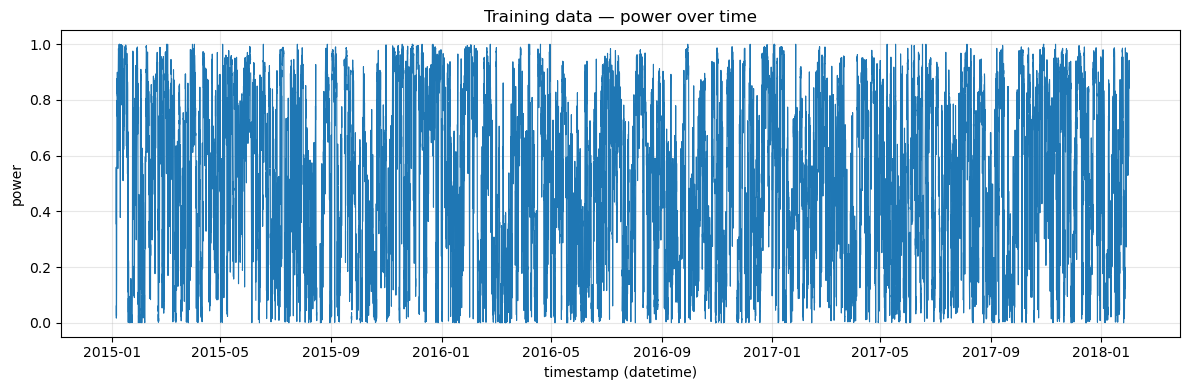

In [13]:
# Plot power over time for training data
training_data = training_data.copy()

# Ensure power is numeric
training_data['power'] = pd.to_numeric(training_data['power'], errors='coerce')

# Try to parse timestamp to datetime; if parsing fails, use numeric/index fallback
training_data['timestamp_parsed'] = pd.to_datetime(training_data['timestamp'], errors='coerce')

if training_data['timestamp_parsed'].isna().all():
    # Couldn't parse timestamps — try numeric conversion, otherwise use index
    try:
        x = pd.to_numeric(training_data['timestamp'], errors='coerce')
        x_label = 'timestamp (numeric)'
        if x.isna().all():
            x = training_data.index
            x_label = 'row index'
    except Exception:
        x = training_data.index
        x_label = 'row index'
else:
    # Use parsed datetimes (and sort for a clean time series)
    training_data = training_data.sort_values('timestamp_parsed')
    x = training_data['timestamp_parsed']
    x_label = 'timestamp (datetime)'

y = training_data['power']

import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
plt.plot(x, y, lw=0.8)
plt.xlabel(x_label)
plt.ylabel('power')
plt.title('Training data — power over time')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
